In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def filtroZero(img, cf):
    if isinstance(img, str):
        img = cv2.imread(img, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise ValueError("No se pudo leer la imagen. Verifica la ruta o formato.")
    
    filas, columnas = img.shape
    m, n = cf.shape
    oF, oC = m // 2, n // 2

    suma_cf = np.sum(cf)
    if suma_cf != 0:
        cf = cf / suma_cf

    img_padded = np.pad(img, ((oF, oF), (oC, oC)), mode='constant', constant_values=0)

    salida = np.zeros_like(img, dtype=float)

    for i in range(filas):
        for j in range(columnas):
            region = img_padded[i:i+m, j:j+n]
            salida[i, j] = np.sum(region * cf)
    
    salida = np.clip(salida, 0, 255).astype(np.uint8)

    # Resultados
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray')
    plt.title('Imagen original')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(salida, cmap='gray')
    plt.title('Imagen filtrada (Zero-padding)')
    plt.axis('off')

    plt.show()

    return salida

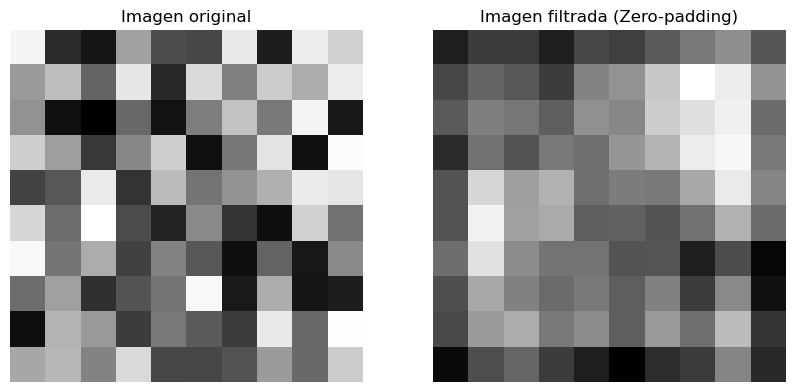

Matriz original: 
 [[244  43  21 160  77  71 231  29 235 207]
 [153 189  99 230  40 217 128 203 171 236]
 [145  16   0 104  18 125 193 121 242  24]
 [206 157  57 135 206  16 118 227  16 251]
 [ 67  87 233  51 187 116 145 175 234 228]
 [213 108 254  75  35 137  53  14 207 114]
 [247 117 171  65 129  87  15  99  23 136]
 [109 159  47  84 115 247  25 172  21  29]
 [ 14 179 152  61 120  91  60 232 105 253]
 [166 181 130 216  71  70  83 153 105 203]] 

Matriz filtrada: 
 [[ 69  83  82  69  88  84  97 110 120  94]
 [ 87 101  95  83 115 122 146 172 163 123]
 [ 96 113 109  98 121 117 149 157 165 104]
 [ 75 107  93 110 106 124 137 163 168 110]
 [ 93 153 128 136 106 112 111 132 162 116]
 [ 93 166 129 133  98 100  93 107 136 104]
 [105 158 119 108 108  93  94  69  90  58]
 [ 91 132 114 104 111  98 114  83 118  63]
 [ 89 126 134 110 119  98 125 106 141  79]
 [ 60  91 102  83  69  55  76  82 116  74]]


In [16]:
# Matriz aleatoria de 10x10
im_random_10 = np.random.randint(0, 256, size=(10, 10), dtype=np.uint8)

cf3 = np.ones((3,3))

res_zero = filtroZero(im_random_10, cf3)
print("Matriz original: \n",im_random_10, "\n")
print("Matriz filtrada: \n", res_zero)
